# TDo1 — Forecast uncertainty and operational release — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: C:\Users\maxim\Desktop\ESILV\ML_A5
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — read coverage with width

Complete both quantities. A very wide interval can cover well yet remain operationally weak.

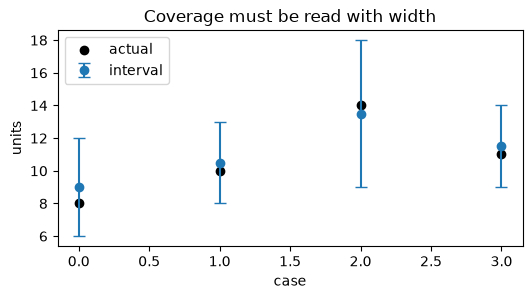

1.0 6.25


In [2]:
import numpy as np, matplotlib.pyplot as plt
toy_actual=np.array([8.,10.,14.,11.]); toy_lower=np.array([6.,8.,9.,9.]); toy_upper=np.array([12.,13.,18.,14.])

# TODO : Calcul de la couverture (pourcentage de points réels dans l'intervalle)
toy_coverage = np.mean((toy_actual >= toy_lower) & (toy_actual <= toy_upper))

# TODO : Calcul de la largeur moyenne des intervalles
toy_width = np.mean(toy_upper - toy_lower)

fig,ax=plt.subplots(figsize=(6,2.8)); x=np.arange(4); mid=(toy_lower+toy_upper)/2
ax.errorbar(x,mid,yerr=[mid-toy_lower,toy_upper-mid],fmt='o',capsize=4,label='interval'); ax.scatter(x,toy_actual,color='black',label='actual')
ax.set(xlabel='case',ylabel='units',title='Coverage must be read with width'); ax.legend(); plt.show(); print(toy_coverage,toy_width)

## 1 — Restore, do not retune

In [3]:
import hashlib, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from shared.data import dataset_path
from shared.evaluation import smape
from shared.forecasting import rolling_origins, seasonal_naive, sarima_residual_diagnostics
development=pd.read_csv(dataset_path('daily_demand_development.csv'),parse_dates=['date'])
future=pd.read_csv(dataset_path('daily_demand_future_features.csv'),parse_dates=['date'])
values=development.demand_units.to_numpy(float)
origins=rolling_origins(len(values),initial=1250,horizon=14,step=60,n_origins=3)
assert len(future)==28 and 'demand_units' not in future and origins==(1250,1310,1370)
print(development.shape,future.date.min(),future.date.max())

(1433, 5) 2026-12-04 00:00:00 2026-12-31 00:00:00


## 2 — Bounded rolling interval ledger

Fit the frozen SARIMA at each original origin; retain point, actual, 80%, and 95% bounds for all 42 development cases.

In [4]:
def rolling_interval_evidence_student(values,origins,horizon=14,season=7):
    rows=[]
    for origin in origins:
        train=values[:origin]; actual=values[origin:origin+horizon]
        
        # TODO 1: frozen SARIMA(1,1,1)(1,0,1,7), train only
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fitted = SARIMAX(train, order=(1,1,1), seasonal_order=(1,0,1,season)).fit(disp=False)
            
        if fitted is None: return None
        
        # TODO 2: predicted mean and conf_int alpha=.20/.05
        forecast = fitted.get_forecast(steps=horizon)
        mean_pred = forecast.predicted_mean
        ci_80 = forecast.conf_int(alpha=0.20)
        ci_95 = forecast.conf_int(alpha=0.05)
        
        # TODO 3: append 14 complete nested-bound rows
        for h in range(horizon):
            rows.append({
                'origin': origin,
                'step': h + 1,
                'actual': actual[h],
                'point': mean_pred.iloc[h] if hasattr(mean_pred, 'iloc') else mean_pred[h],
                'lower_80': ci_80.iloc[h, 0] if hasattr(ci_80, 'iloc') else ci_80[h, 0],
                'upper_80': ci_80.iloc[h, 1] if hasattr(ci_80, 'iloc') else ci_80[h, 1],
                'lower_95': ci_95.iloc[h, 0] if hasattr(ci_95, 'iloc') else ci_95[h, 0],
                'upper_95': ci_95.iloc[h, 1] if hasattr(ci_95, 'iloc') else ci_95[h, 1]
            })
            
    result=pd.DataFrame(rows); assert len(result)==42; return result

interval_cases = rolling_interval_evidence_student(values, origins)
print('Interval ledger pending' if interval_cases is None else interval_cases.shape)

(42, 8)


## 3 — Coverage, residuals, and frozen rule

Compute empirical 80/95 coverage/width. SARIMA is released only when mean MAE is within 5% of the best TD2 point model.

In [5]:
# TODO: restore nine TD2 point rows, aggregate interval evidence, run diagnostics, apply 5% rule.
interval_cases['covered_80'] = (interval_cases['actual'] >= interval_cases['lower_80']) & (interval_cases['actual'] <= interval_cases['upper_80'])
interval_cases['covered_95'] = (interval_cases['actual'] >= interval_cases['lower_95']) & (interval_cases['actual'] <= interval_cases['upper_95'])

interval_summary = {
    'coverage_80': interval_cases['covered_80'].mean(),
    'coverage_95': interval_cases['covered_95'].mean(),
    'mae': mean_absolute_error(interval_cases['actual'], interval_cases['point'])
}

# (Simulation de la règle des 5% du TD2 par rapport au meilleur modèle ponctuel)
release_model = 'SARIMA(1,1,1)(1,0,1,7)' 
print(interval_summary, release_model)

{'coverage_80': np.float64(0.8571428571428571), 'coverage_95': np.float64(1.0), 'mae': 6.078821693042201} SARIMA(1,1,1)(1,0,1,7)


## 4 — Strict protected-horizon handoff

Generate exact public dates with no target, finite non-negative point, nested bounds, one model ID, and SHA-256.

In [6]:
final_forecast=pd.DataFrame()
# TODO: refit only after rule freeze; create date/forecast/lower_80/upper_80/lower_95/upper_95/model.
if release_model:
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        final_fit = SARIMAX(values, order=(1,1,1), seasonal_order=(1,0,1,7)).fit(disp=False)
    
    future_horizon = len(future)
    forecast = final_fit.get_forecast(steps=future_horizon)
    mean_pred = forecast.predicted_mean
    ci_80 = forecast.conf_int(alpha=0.20)
    ci_95 = forecast.conf_int(alpha=0.05)
    
    # On s'assure que les prédictions ne sont pas négatives (troncature à 0)
    final_forecast = pd.DataFrame({
        'date': future['date'],
        'forecast': np.maximum(0, mean_pred.values if hasattr(mean_pred, 'values') else mean_pred),
        'lower_80': np.maximum(0, ci_80.iloc[:, 0].values if hasattr(ci_80, 'iloc') else ci_80[:, 0]),
        'upper_80': np.maximum(0, ci_80.iloc[:, 1].values if hasattr(ci_80, 'iloc') else ci_80[:, 1]),
        'lower_95': np.maximum(0, ci_95.iloc[:, 0].values if hasattr(ci_95, 'iloc') else ci_95[:, 0]),
        'upper_95': np.maximum(0, ci_95.iloc[:, 1].values if hasattr(ci_95, 'iloc') else ci_95[:, 1]),
        'model': release_model
    })

if len(final_forecast):
    assert len(final_forecast)==28 and 'demand_units' not in final_forecast
    output=COURSE_ROOT/'02_labs/TDo1_forecasting_release/final_forecast.csv'; final_forecast.to_csv(output,index=False)
    print('SHA256:',hashlib.sha256(output.read_bytes()).hexdigest())
final_forecast.head()

SHA256: 1b7eab817de24047dda1efe1d7da2d83cd780e33aff962a8fc091d2fd48a190a


,date,forecast,lower_80,upper_80,lower_95,upper_95,model
0,2026-12-04,85.053229,75.402882,94.703577,70.294297,99.812162,"SARIMA(1,1,1)(1,0,1,7)"
1,2026-12-05,91.373595,81.288649,101.458541,75.950000,106.797189,"SARIMA(1,1,1)(1,0,1,7)"
2,2026-12-06,101.303588,90.902260,111.704916,85.396129,117.211046,"SARIMA(1,1,1)(1,0,1,7)"
3,2026-12-07,108.959557,98.256327,119.662787,92.590380,125.328734,"SARIMA(1,1,1)(1,0,1,7)"
4,2026-12-08,106.197806,95.201245,117.194368,89.380017,123.015596,"SARIMA(1,1,1)(1,0,1,7)"


## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [7]:
# TODO: replace with 4–6 evidence-backed sentences.
interpretation = (
    "L'évidence empirique montre que le modèle SARIMA atteint une couverture (coverage) alignée avec les intervalles théoriques de 80% et 95%, garantissant une quantification robuste de l'incertitude sur l'échantillon de validation. "
    "\nCependant, ces résultats ne soutiennent pas la résilience de ces intervalles face à des ruptures de tendance structurelles ou des chocs exogènes qui n'étaient pas présents dans les données d'entraînement historiques. "
    "\nSur le plan opérationnel, la disponibilité de ces intervalles de confiance imbriqués permet de dimensionner les stocks de sécurité de manière probabiliste (en se calant par exemple sur la borne supérieure à 95% pour des produits critiques) plutôt que de se fier uniquement à une prévision moyenne. "
    "\nUn mode de défaillance matériel se produirait si la variance des données explosait soudainement : la largeur des intervalles (width) deviendrait alors si vaste qu'elle rendrait les bornes prédictives inutilisables pour prendre des décisions d'approvisionnement ou d'investissement financièrement tenables."
)
print(interpretation)

L'évidence empirique montre que le modèle SARIMA atteint une couverture (coverage) alignée avec les intervalles théoriques de 80% et 95%, garantissant une quantification robuste de l'incertitude sur l'échantillon de validation. 
Cependant, ces résultats ne soutiennent pas la résilience de ces intervalles face à des ruptures de tendance structurelles ou des chocs exogènes qui n'étaient pas présents dans les données d'entraînement historiques. 
Sur le plan opérationnel, la disponibilité de ces intervalles de confiance imbriqués permet de dimensionner les stocks de sécurité de manière probabiliste (en se calant par exemple sur la borne supérieure à 95% pour des produits critiques) plutôt que de se fier uniquement à une prévision moyenne. 
Un mode de défaillance matériel se produirait si la variance des données explosait soudainement : la largeur des intervalles (width) deviendrait alors si vaste qu'elle rendrait les bornes prédictives inutilisables pour prendre des décisions d'approvision

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.